<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat%2Fmodels/notebooks/model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1: GitHub Repository Configuration and Branch Setup

In this step, we configure Git credentials (user name and email), clone the main project repository from GitHub,  
and create a new feature branch for our work.  

In [1]:
# Configure Git identity
!git config --global user.email "indrachapavithanage306@gmail.com"
!git config --global user.name "SandaminiI"

# Define repository information
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"
TOKEN = "token"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}

# Create a new feature branch
#BRANCH = "feat/models"
!git checkout -b feat/models

Cloning into 'fake-news-detection'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 92 (delta 43), reused 28 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 2.05 MiB | 12.89 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/fake-news-detection
Switched to a new branch 'feat/models'


## Step 2: Environment Setup and Library Installation

In [2]:
!pip -q install pandas numpy scikit-learn tensorflow torch transformers matplotlib

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import os, pathlib

os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/figs", exist_ok=True)

!ls -lah data/processed

total 8.0K
drwxr-xr-x 2 root root 4.0K Oct 10 19:51 .
drwxr-xr-x 3 root root 4.0K Oct 10 19:51 ..


## Step 3: Upload and Load the Dataset

In this step, upload the preprocessed CSV files (`train.csv`, `val.csv`, and `test.csv`)  
from the local system to the Colab environment using the `files.upload()` function.

Then, we:
- Move the uploaded files into the `data/processed/` directory.
- Load the datasets into Pandas DataFrames for analysis and model training.
- Display the shapes of the three datasets to confirm successful loading.

In [3]:
from google.colab import files
uploaded = files.upload()    # choose train.csv, val.csv, test.csv

Saving test.csv to test.csv
Saving train.csv to train.csv
Saving val.csv to val.csv


In [4]:
import os
os.makedirs("data/processed", exist_ok=True)

# Move uploaded files to the processed data directory
!mv train.csv data/processed/train.csv
!mv val.csv data/processed/val.csv
!mv test.csv data/processed/test.csv

# Verify that the files exist in the correct folder
!ls data/processed

test.csv  train.csv  val.csv


In [ ]:
# Load datasets into pandas DataFrames
train = pd.read_csv("data/processed/train.csv")
val   = pd.read_csv("data/processed/val.csv")
test  = pd.read_csv("data/processed/test.csv")

print(train.shape, val.shape, test.shape)

## Step 4: Model Training and Performance Comparison  

In this section, we train and evaluate four models on the fake news dataset:  


1. **Long Short-Term Memory (LSTM)** – a recurrent neural network that captures word order and context.  
2. BI LSTM
After training, each model’s accuracy and F1-score are compared, and the best-performing model is identified.

## Model 1 – LSTM (Long Short-Term Memory)

- **Model Type:** Deep learning model using Long Short-Term Memory (LSTM).  

- **Purpose:** Detect fake news by learning word order and context in sentences.  

- **Input Processing:**  
  - Texts are tokenized into integer sequences.  
  - Sequences are padded to a fixed length (300 words).  

- **Architecture:**  
  - **Embedding layer** – Converts words into dense 128-dimensional vectors.  
  - **LSTM layer** – Learns contextual and sequential relationships between words.  
  - **Dense (sigmoid) output layer** – Produces probability of “fake” or “real”.  

- **Training Details:**  
  - Optimizer: **Adam**  
  - Loss Function: **Binary Cross-Entropy**  
  - Epochs: **3**, Batch Size: **128**  

- **Advantages:**  
  - Captures **long-term dependencies** in text.  
  - Understands **semantic meaning** beyond simple word counts.  

- **Evaluation Metrics:**  
  - **Accuracy** and **F1-Score** used to assess model performance.  


In [ ]:
#import necessary libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Tokenize
tokenizer = Tokenizer(num_words=20000, oov_token='<OOV>')
tokenizer.fit_on_texts(train['text_clean'])

train_seq = tokenizer.texts_to_sequences(train['text_clean'])
val_seq   = tokenizer.texts_to_sequences(val['text_clean'])
test_seq  = tokenizer.texts_to_sequences(test['text_clean'])

max_len = 300
X_train_pad = pad_sequences(train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(test_seq, maxlen=max_len)

# Build the LSTM model
model = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    LSTM(128, dropout=0.3, recurrent_dropout=0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train_pad, train['label'],
                    validation_data=(X_val_pad, val['label']),
                    epochs=3, batch_size=128)

# Helper function for evaluating models
def eval_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    print(f"{name} → Accuracy:{acc:.4f}, F1:{f1:.4f}")
    return acc, f1

# Predict and evaluate
pred_lstm = (model.predict(X_test_pad) > 0.5).astype('int32')
res['LSTM'] = eval_model('LSTM', test['label'], pred_lstm)

Epoch 1/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 626s 2s/step - accuracy: 0.9135 - loss: 0.2575 - val_accuracy: 0.9869 - val_loss: 0.0506
Epoch 2/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 605s 2s/step - accuracy: 0.9846 - loss: 0.0511 - val_accuracy: 0.9746 - val_loss: 0.0731
Epoch 3/3
294/294 ━━━━━━━━━━━━━━━━━━━━ 608s 2s/step - accuracy: 0.9883 - loss: 0.0333 - val_accuracy: 0.9844 - val_loss: 0.0504
141/141 ━━━━━━━━━━━━━━━━━━━━ 19s 134ms/step
LSTM → Accuracy:0.9828, F1:0.9836


# Model 2 - Bi LSTM

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import accuracy_score, f1_score

# Helper function for evaluating models
def eval_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    print(f"{name} → Accuracy:{acc:.4f}, F1:{f1:.4f}")
    return acc, f1

# Tokenize
tokenizer = Tokenizer(num_words=20000, oov_token='<OOV>')
tokenizer.fit_on_texts(train['text_clean'])

train_seq = tokenizer.texts_to_sequences(train['text_clean'])
val_seq   = tokenizer.texts_to_sequences(val['text_clean'])
test_seq  = tokenizer.texts_to_sequences(test['text_clean'])

max_len = 300
X_train_pad = pad_sequences(train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(test_seq, maxlen=max_len)


model_bilstm = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    Bidirectional(LSTM(128, dropout=0.3, recurrent_dropout=0.3)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_bilstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history_bilstm = model_bilstm.fit(X_train_pad, train['label'],
                                  validation_data=(X_val_pad, val['label']),
                                  epochs=3, batch_size=128)

# Evaluate
pred_bilstm = (model_bilstm.predict(X_test_pad) > 0.5).astype('int32')
res['BiLSTM'] = eval_model('BiLSTM', test['label'], pred_bilstm)

# Model 3 - RNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

# --- Data Preparation (uses the same tokenizer as before) ---
tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(train['text_clean'])

# Convert text to sequences
train_seq = tokenizer.texts_to_sequences(train['text_clean'])
val_seq   = tokenizer.texts_to_sequences(val['text_clean'])
test_seq  = tokenizer.texts_to_sequences(test['text_clean'])

# Pad sequences to same length
max_len = 300
X_train_pad = pad_sequences(train_seq, maxlen=max_len)
X_val_pad   = pad_sequences(val_seq, maxlen=max_len)
X_test_pad  = pad_sequences(test_seq, maxlen=max_len)

# --- Model Architecture ---
model_rnn = Sequential([
    Embedding(input_dim=20000, output_dim=128, input_length=max_len),
    SimpleRNN(128, activation='tanh', dropout=0.3, recurrent_dropout=0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# --- Compile Model ---
model_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --- Train Model ---
history_rnn = model_rnn.fit(
    X_train_pad, train['label'],
    validation_data=(X_val_pad, val['label']),
    epochs=3,
    batch_size=128
)

# --- Evaluate on Test Set ---
pred_rnn = (model_rnn.predict(X_test_pad) > 0.5).astype('int32')

# --- Log Results ---
res['SimpleRNN'] = eval_model('SimpleRNN', test['label'], pred_rnn)


CNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

model_cnn = Sequential([
    Embedding(input_dim=20000, output_dim=128, input_length=300),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_cnn.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history_cnn = model_cnn.fit(X_train_pad, train['label'],
                            validation_data=(X_val_pad, val['label']),
                            epochs=3, batch_size=128)

# Evaluate
pred_cnn = (model_cnn.predict(X_test_pad) > 0.5).astype('int32')
res['CNN'] = eval_model('CNN', test['label'], pred_cnn)


## Model 4 - TF-IDF + Logistic Regression

This model combines the **TF-IDF vectorization technique** with a **Logistic Regression classifier** to detect fake news.

### How it works
1. **TF-IDF (Term Frequency – Inverse Document Frequency):**  
   Converts each news article or headline into a numerical feature vector that captures how important a word is within a document relative to the whole dataset.  
   - Rare but informative words get higher weights.  
   - Common words (like “the”, “is”, “and”) get lower weights.

2. **Logistic Regression Classifier:**  
   Learns to separate *real* vs *fake* news based on the TF-IDF vectors.  
   It outputs the probability that a given news text belongs to the "Fake" class.

### Why use this model
- Lightweight and fast to train.  
- Very effective for textual datasets even without deep learning.  
- Provides interpretability — you can inspect which words contribute most to fake or real predictions.

TFIDF_LogReg → Accuracy:0.9909, F1:0.9912
TFIDF_LogReg → Accuracy:0.9909, F1:0.9912


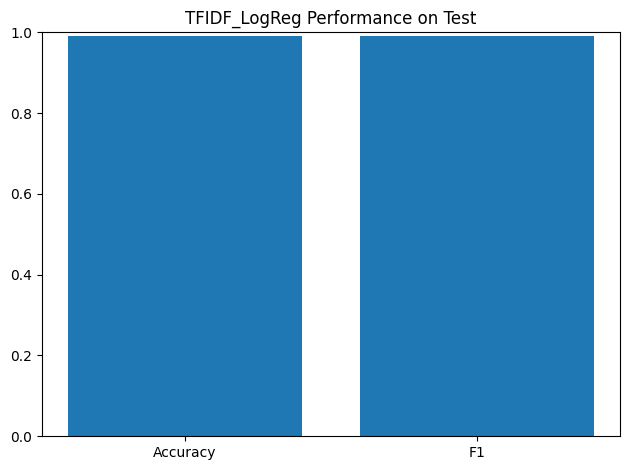

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

# Use train+val to learn final model, test for evaluation
X_train = pd.concat([train['text_clean'], val['text_clean']], axis=0).values
y_train = pd.concat([train['label'],      val['label']],      axis=0).values
X_test  = test['text_clean'].values
y_test  = test['label'].values

# Vectorize text
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=2)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

# Train classifier
clf = LogisticRegression(max_iter=500, n_jobs=-1)
clf.fit(Xtr, y_train)

# Predict on test
y_pred = clf.predict(Xte)

# Log metrics (update the key name if your notebook expects 'DistilBERT')
res_key = 'TFIDF_LogReg'   # change to 'DistilBERT' if your later code expects that key
acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred)
print(f"{res_key} → Accuracy:{acc:.4f}, F1:{f1:.4f}")

# If you have eval_model() defined earlier:
try:
    res[res_key] = eval_model(res_key, y_test, y_pred)
except NameError:
    # Fallback if eval_model isn't defined
    if 'res' not in globals():
        res = {}
    res[res_key] = (acc, f1)

# save small artifacts to keep parity with your pipeline
import os, joblib, matplotlib.pyplot as plt
os.makedirs('results/metrics', exist_ok=True)
os.makedirs('results/models',  exist_ok=True)
os.makedirs('results/figs',    exist_ok=True)

# Save metrics table
pd.DataFrame([{'Model':res_key, 'Accuracy':acc, 'F1':f1}]
            ).to_csv('results/metrics/model_metrics_tfidf_logreg.csv', index=False)

# Save model for Member D
joblib.dump(tfidf, 'results/models/tfidf.joblib')
joblib.dump(clf,   'results/models/logreg.joblib')

# Quick bar plot
plt.bar(['Accuracy','F1'], [acc, f1])
plt.ylim(0,1)
plt.title(f'{res_key} Performance on Test')
plt.tight_layout()
plt.savefig('results/figs/tfidf_logreg_performance.png')
plt.show()

## Step 5: Compare and Visualize Model Performance

After training all models (Logistic Regression, SVM, LSTM, and TF-IDF + Logistic Regression),  
Summarize their **accuracy** and **F1 scores** in a single table and visualize them as a bar chart.

This step helps us:
- Identify which model performs best overall.  
- Provide a clear comparison

          Model  Accuracy        F1
0            LR  0.990421  0.990798
1           SVM  0.997550  0.997656
2          LSTM  0.982847  0.983621
3  TFIDF_LogReg  0.990867  0.991234


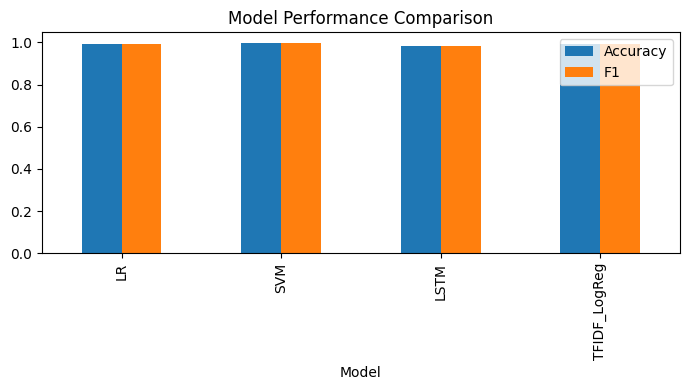

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs('results/figs', exist_ok=True)

# Convert model results dictionary into a DataFrame
# 'res' contains accuracy & F1 for each trained model
df_res = pd.DataFrame(
    [(k, v[0], v[1]) for k, v in res.items()],
    columns=['Model', 'Accuracy', 'F1']
)

# Save results to CSV for record keeping
df_res.to_csv('results/model_metrics.csv', index=False)
print(df_res)

# Plot accuracy and F1-score comparison
df_res.plot(x='Model', y=['Accuracy', 'F1'], kind='bar', figsize=(7, 4))
plt.title('Model Performance Comparison')
plt.tight_layout()
plt.savefig('results/figs/model_comparison.png')
plt.show()

## Step 6: Save All Trained Models and Artifacts for Deployment

In this step, we save every trained model, vectorizer, and tokenizer so they can be reused. All files are stored in the `results/models/` directory.

In [ ]:
import joblib, os

# Create directory
os.makedirs('results/models', exist_ok=True)

# Save Classical Models
joblib.dump(lr,   'results/models/logreg.joblib')           # baseline Logistic Regression
joblib.dump(svm,  'results/models/svm.joblib')              # Support Vector Machine

# Save TF-IDF Vectorizer & TF-IDF + Logistic Regression Model
joblib.dump(tfidf,        'results/models/tfidf_vectorizer.joblib')
joblib.dump(clf,          'results/models/tfidf_logreg.joblib')      # TF-IDF + LogReg model

# Save LSTM Model & Tokenizer
model.save('results/models/lstm.keras')
joblib.dump(tokenizer, 'results/models/lstm_tokenizer.joblib')

print("All models, vectorizers, and tokenizer saved in results/models/ (LSTM saved in .keras format)")
!ls -lh results/models


All models, vectorizers, and tokenizer saved in results/models/ (LSTM saved in .keras format)
total 69M
-rw-r--r-- 1 root root 158K Oct 10 12:42 logreg.joblib
-rw-r--r-- 1 root root  31M Oct 10 12:26 lstm.h5
-rw-r--r-- 1 root root  31M Oct 10 12:42 lstm.keras
-rw-r--r-- 1 root root 4.5M Oct 10 12:42 lstm_tokenizer.joblib
-rw-r--r-- 1 root root 157K Oct 10 12:42 svm.joblib
-rw-r--r-- 1 root root 770K Oct 10 12:26 tfidf.joblib
-rw-r--r-- 1 root root 158K Oct 10 12:42 tfidf_logreg.joblib
-rw-r--r-- 1 root root 770K Oct 10 12:42 tfidf_vectorizer.joblib


## Step 7: Backup Models to Google Drive

After successfully training and saving all models, we back them up to Google Drive to ensure the artifacts are safely stored and accessible  
for evaluation.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p '/content/drive/MyDrive/fake_news_project/models'
!cp results/models/* '/content/drive/MyDrive/fake_news_project/models/'
print("Models copied to Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models copied to Google Drive.


**Github upload**

In [ ]:
!git add -f results/model_metrics.csv \
           results/figs/model_comparison.png \
           results/figs/tfidf_logreg_performance.png \
!git commit -m "Model training (LR, SVM, TFIDF_LogReg, LSTM)"
!git push --set-upstream origin feat/models